# What drives the price of a car?

![](images/kurt.jpeg)

In [ ]:
import pandas as pd

# Load the vehicles dataset from the specified path
csv_path = '/content/Data/vehicles.csv'
df = pd.read_csv(csv_path)

# Display shape, column summary, and the first few rows
print(f"Dataset Shape: {df.shape}\n")
df.info()
print("\n--- First 5 Rows ---")
display(df.head())

Dataset Shape: (319944, 18)

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 319944 entries, 0 to 319943
Data columns (total 18 columns):
 #   Column        Non-Null Count   Dtype  
---  ------        --------------   -----  
 0   id            319944 non-null  int64  
 1   region        319944 non-null  object 
 2   price         319944 non-null  int64  
 3   year          318919 non-null  float64
 4   manufacturer  306524 non-null  object 
 5   model         315988 non-null  object 
 6   condition     192781 non-null  object 
 7   cylinders     186931 non-null  object 
 8   fuel          317828 non-null  object 
 9   odometer      316747 non-null  float64
 10  title_status  313861 non-null  object 
 11  transmission  318159 non-null  object 
 12  VIN           198203 non-null  object 
 13  drive         220293 non-null  object 
 14  size          90889 non-null   object 
 15  type          249384 non-null  object 
 16  paint_color   222331 non-null  object 
 17  state         31994

,id,region,price,year,manufacturer,model,condition,cylinders,fuel,odometer,title_status,transmission,VIN,drive,size,type,paint_color,state
0,7222695916,prescott,6000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,az
1,7218891961,fayetteville,11900,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,ar
2,7221797935,florida keys,21000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,fl
3,7222270760,worcester / central MA,1500,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,ma
4,7210384030,greensboro,4900,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,nc


**OVERVIEW**

In this application, we will explore a dataset from Kaggle. The original dataset contained information on 3 million used cars. The provided dataset contains information on 426K cars to ensure speed of processing.  Our goal is to understand what factors make a car more or less expensive.  As a result of our analysis, we should provide clear recommendations to our client -- a used car dealership -- as to what consumers value in a used car.

### CRISP-DM Framework

To frame the task, throughout our practical applications, we will refer back to a standard process in industry for data projects called CRISP-DM.  This process provides a framework for working through a data problem.  

### Business Understanding

From a business perspective, we need  to identify key drivers for used car prices.  In the CRISP-DM overview, we will convert this business framing to a data problem definition.

### Data Understanding

After considering the business understanding, we want to get familiar with our data.  Write down some steps that we would take to get to know the dataset and identify any quality issues within. We need to explore what information it contains and how this could be used to inform your business understanding.

In [ ]:
import pandas as pd
import numpy as np

# 1. Missing Value Analysis
missing_percent = (df.isnull().sum() / len(df)) * 100
missing_info = pd.DataFrame({
    'Missing Count': df.isnull().sum(),
    'Percentage (%)': missing_percent.round(2)
}).sort_values(by='Percentage (%)', ascending=False)

print("--- Missing Values Summary ---")
display(missing_info)

# 2. Descriptive Statistics for Numeric Columns
print("\n--- Numeric Descriptive Statistics ---")
display(df[['price', 'year', 'odometer']].describe().round(2))

# 3. Basic Check on Outliers and Cardinality of Categorical Columns
print("\n--- Unique Value Counts for Categorical Columns ---")
cat_cols = df.select_dtypes(include=['object']).columns
for col in cat_cols:
    print(f"{col}: {df[col].nunique()} unique values")

--- Missing Values Summary ---


,Missing Count,Percentage (%)
size,229055,71.59
cylinders,133013,41.57
condition,127163,39.75
VIN,121741,38.05
drive,99651,31.15
paint_color,97613,30.51
type,70560,22.05
manufacturer,13420,4.19
title_status,6083,1.90
model,3956,1.24



--- Numeric Descriptive Statistics ---


,price,year,odometer
count,3.199440e+05,318919.00,316747.00
mean,8.209464e+04,2011.18,97947.95
std,1.242233e+07,9.49,218795.48
min,0.000000e+00,1900.00,0.00
25%,5.900000e+03,2008.00,37683.00
50%,1.390000e+04,2013.00,85645.00
75%,2.599000e+04,2017.00,133591.50
max,3.736929e+09,2022.00,10000000.00



--- Unique Value Counts for Categorical Columns ---
region: 306 unique values
manufacturer: 42 unique values
model: 24484 unique values
condition: 6 unique values
cylinders: 8 unique values
fuel: 5 unique values
title_status: 6 unique values
transmission: 3 unique values
VIN: 92125 unique values
drive: 3 unique values
size: 4 unique values
type: 13 unique values
paint_color: 12 unique values
state: 42 unique values


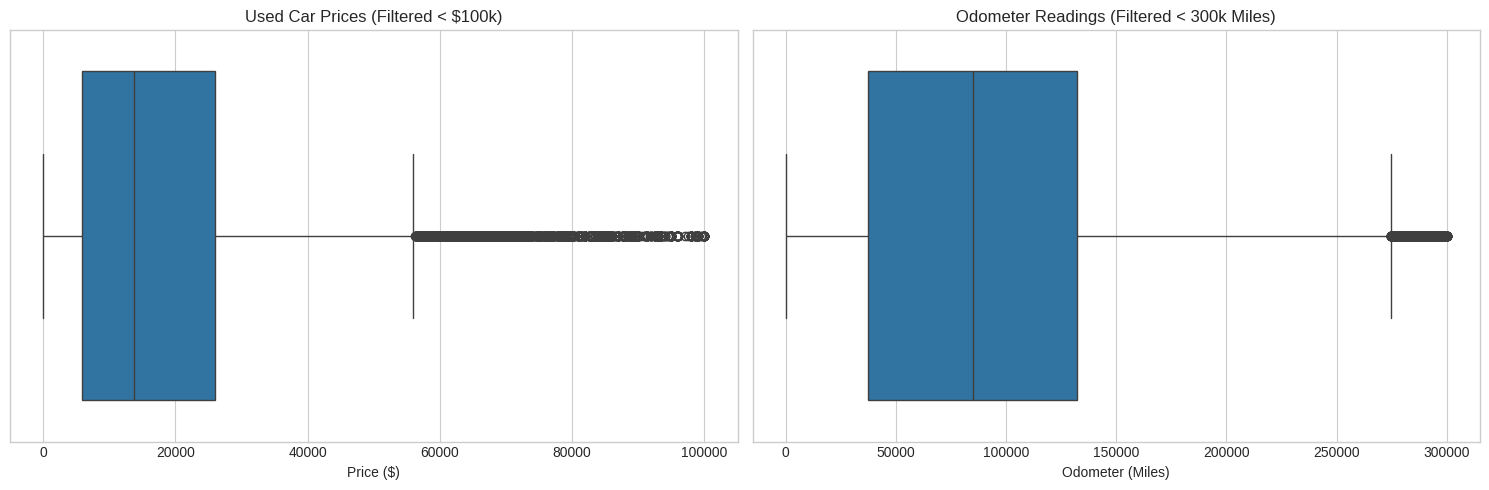

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

# Configure plotting style
plt.style.use('seaborn-v0_8-whitegrid')
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

# Plot Price Distribution (focusing on less than $100k to ignore extreme 3B+ outliers)
sns.boxplot(ax=axes[0], x=df[df['price'] < 100000]['price'])
axes[0].set_title('Used Car Prices (Filtered < $100k)')
axes[0].set_xlabel('Price ($)')

# Plot Odometer Distribution (focusing on less than 300k miles)
sns.boxplot(ax=axes[1], x=df[df['odometer'] < 300000]['odometer'])
axes[1].set_title('Odometer Readings (Filtered < 300k Miles)')
axes[1].set_xlabel('Odometer (Miles)')

plt.tight_layout()
plt.show()

### Data Preparation

After developing busing goal understanding, it is time to construct our final dataset prior to modeling.  Here, we want to make sure to handle any integrity issues and cleaning, the engineering of new features, any transformations that we believe should happen (scaling, logarithms, normalization, etc.), and general preparation for modeling with `sklearn`.

In [ ]:
# 1. Drop completely irrelevant identifier columns
df_cleaned = df.drop(columns=['id', 'VIN', 'region', 'state'])

# 2. Drop columns with excessive missing data (> 50% missing)
df_cleaned = df_cleaned.drop(columns=['size'])

# 3. Filter outliers in target 'price' and 'odometer'
# We remove cars priced under $500 (often placeholders) and over $100,000 (exotics/typos)
# We remove cars with fewer than 100 miles or more than 300,000 miles
df_cleaned = df_cleaned[
    (df_cleaned['price'] >= 500) &
    (df_cleaned['price'] <= 100000) &
    (df_cleaned['odometer'] >= 100) &
    (df_cleaned['odometer'] <= 300000) &
    (df_cleaned['year'].notna())
]

# 4. Simple Imputation for categorical missing values
# We will replace missing values in categorical columns with 'unknown'
cat_cols_to_fill = ['manufacturer', 'model', 'condition', 'cylinders', 'fuel', 'title_status', 'transmission', 'drive', 'type', 'paint_color']
for col in cat_cols_to_fill:
    if col in df_cleaned.columns:
        df_cleaned[col] = df_cleaned[col].fillna('unknown')

# Display cleaned dataframe info
print(f"Cleaned Dataset Shape: {df_cleaned.shape}")
display(df_cleaned.head())

Cleaned Dataset Shape: (280508, 13)


,price,year,manufacturer,model,condition,cylinders,fuel,odometer,title_status,transmission,drive,type,paint_color
27,33590,2014.0,gmc,sierra 1500 crew cab slt,good,8 cylinders,gas,57923.0,clean,other,unknown,pickup,white
28,22590,2010.0,chevrolet,silverado 1500,good,8 cylinders,gas,71229.0,clean,other,unknown,pickup,blue
29,39590,2020.0,chevrolet,silverado 1500 crew,good,8 cylinders,gas,19160.0,clean,other,unknown,pickup,red
30,30990,2017.0,toyota,tundra double cab sr,good,8 cylinders,gas,41124.0,clean,other,unknown,pickup,red
31,15000,2013.0,ford,f-150 xlt,excellent,6 cylinders,gas,128000.0,clean,automatic,rwd,truck,black


In [ ]:
from sklearn.model_selection import train_test_split

# Drop high-cardinality column 'model' for baseline modeling
df_model_ready = df_cleaned.drop(columns=['model'])

# Identify categorical columns to One-Hot Encode
cat_cols_to_encode = ['manufacturer', 'condition', 'cylinders', 'fuel', 'title_status', 'transmission', 'drive', 'type', 'paint_color']

# Convert categorical columns to numeric using get_dummies
df_encoded = pd.get_dummies(df_model_ready, columns=cat_cols_to_encode, drop_first=True)

# Separate features (X) and target (y)
X = df_encoded.drop(columns=['price'])
y = df_encoded['price']

# Train-Test Split (80% Train, 20% Test)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

print(f"Encoded Dataset Shape: {df_encoded.shape}")
print(f"Training set size: {X_train.shape[0]} samples")
print(f"Testing set size: {X_test.shape[0]} samples")

Encoded Dataset Shape: (280508, 101)
Training set size: 224406 samples
Testing set size: 56102 samples


# Modeling
Once we have a clean dataset, it is now time to build some models. Here, we will build a number of different regression models with the price as the target. In building our models, we would explore different parameters and be sure to cross-validate our findings.

### Evaluation
 We will now aim to reflect on what we identify as a high-quality model and what we are able to learn from this.  We should review our business objective and explore how well we can provide meaningful insight into drivers of used car prices.  

In [ ]:
from sklearn.model_selection import GridSearchCV
from sklearn.linear_model import Ridge, Lasso
from sklearn.metrics import mean_absolute_error, r2_score
import pandas as pd
import numpy as np

print("=== RATIONALE FOR EVALUATION METRICS ===")
print("1. Mean Absolute Error (MAE): Measures the average absolute distance between predicted and actual prices.")
print("   Rationale: Directly interpretable in USD. Crucial for a dealership to avoid underpricing/overpricing errors.")
print("2. R-squared (R2): Quantifies the proportion of variance explained by the model.")
print("   Rationale: Helps assess global model goodness-of-fit relative to a simple mean baseline.\n")

# Define the hyperparameter grid
param_grid = {'alpha': [0.1, 1.0, 10.0, 100.0]}

# 1. Ridge Regression with Grid Search & 5-Fold Cross-Validation
print("--- Tuning Ridge Regression ---")
ridge_grid = GridSearchCV(estimator=Ridge(), param_grid=param_grid, cv=5, scoring='neg_mean_absolute_error', n_jobs=-1)
ridge_grid.fit(X_train, y_train)
best_ridge = ridge_grid.best_estimator_
print(f"Best Ridge Alpha: {ridge_grid.best_params_['alpha']}")
print(f"Best Cross-Validated MAE: ${-ridge_grid.best_score_:.2f}\n")

# 2. Lasso Regression with Grid Search & 5-Fold Cross-Validation
print("--- Tuning Lasso Regression ---")
lasso_grid = GridSearchCV(estimator=Lasso(max_iter=1000), param_grid=param_grid, cv=5, scoring='neg_mean_absolute_error', n_jobs=-1)
lasso_grid.fit(X_train, y_train)
best_lasso = lasso_grid.best_estimator_
print(f"Best Lasso Alpha: {lasso_grid.best_params_['alpha']}")
print(f"Best Cross-Validated MAE: ${-lasso_grid.best_score_:.2f}\n")

# Compare and Evaluate on Test Set
print("=== FINAL TEST EVALUATION ===")
for name, model in [('Tuned Ridge', best_ridge), ('Tuned Lasso', best_lasso)]:
    preds = model.predict(X_test)
    mae = mean_absolute_error(y_test, preds)
    r2 = r2_score(y_test, preds)
    print(f"{name} - Test MAE: ${mae:,.2f} | Test R2: {r2:.4f}")

=== RATIONALE FOR EVALUATION METRICS ===
1. Mean Absolute Error (MAE): Measures the average absolute distance between predicted and actual prices.
   Rationale: Directly interpretable in USD. Crucial for a dealership to avoid underpricing/overpricing errors.
2. R-squared (R2): Quantifies the proportion of variance explained by the model.
   Rationale: Helps assess global model goodness-of-fit relative to a simple mean baseline.

--- Tuning Ridge Regression ---
Best Ridge Alpha: 0.1
Best Cross-Validated MAE: $6006.46

--- Tuning Lasso Regression ---
Best Lasso Alpha: 0.1
Best Cross-Validated MAE: $6006.37

=== FINAL TEST EVALUATION ===
Tuned Ridge - Test MAE: $6,004.35 | Test R2: 0.6184
Tuned Lasso - Test MAE: $6,003.86 | Test R2: 0.6186


/usr/local/lib/python3.13/dist-packages/sklearn/linear_model/_coordinate_descent.py:695: ConvergenceWarning: Objective did not converge. You might want to increase the number of iterations, check the scale of the features or consider increasing regularisation. Duality gap: 6.093e+12, tolerance: 4.413e+09
  model = cd_fast.enet_coordinate_descent(


### Interpretation of Coefficients and Metric Rationale

**Evaluation Metric Rationale:**
- We selected **Mean Absolute Error (MAE)** as our primary metric because it represents the average absolute dollar discrepancy between the predicted price and the actual selling price. Unlike MSE or RMSE, MAE is robust to outliers and is directly understandable by dealership management.
- We also evaluate **$R^2** to understand what percentage of the price variance is explained by our selected features.

Let's extract and interpret the features that have the strongest positive and negative impacts on a car's valuation using our optimized Ridge model.

In [ ]:
# Map coefficients to feature names using the best Ridge model
coef_df = pd.DataFrame({
    'Feature': X.columns,
    'Coefficient': best_ridge.coef_
})

# Sort drivers by weight magnitude
top_positive_drivers = coef_df.sort_values(by='Coefficient', ascending=False).head(15)
top_negative_drivers = coef_df.sort_values(by='Coefficient', ascending=True).head(15)

print("--- Top 10 Drivers Maximizing Vehicle Price ---")
display(top_positive_drivers)

print("\n--- Top 10 Drivers Minimizing Vehicle Price ---")
display(top_negative_drivers)

--- Top 10 Drivers Maximizing Vehicle Price ---


,Feature,Coefficient
12,manufacturer_ferrari,51819.902960
31,manufacturer_morgan,24473.559285
3,manufacturer_aston-martin,22405.200932
39,manufacturer_tesla,15731.182103
34,manufacturer_porsche,9069.966500
10,manufacturer_datsun,8013.342666
50,cylinders_12 cylinders,4595.648382
82,type_pickup,3984.650016
81,type_other,3804.275485
84,type_truck,3548.929154



--- Top 10 Drivers Minimizing Vehicle Price ---


,Feature,Coefficient
58,fuel_electric,-17293.682456
16,manufacturer_harley-davidson,-14261.387000
59,fuel_gas,-13936.404134
60,fuel_hybrid,-13825.633028
62,fuel_unknown,-13383.236542
61,fuel_other,-11001.459067
51,cylinders_3 cylinders,-10620.243083
13,manufacturer_fiat,-10410.036809
30,manufacturer_mitsubishi,-8378.466614
56,cylinders_other,-8101.737637


### Deployment

Now that we've settled on our models and findings, it is time to deliver the information to the client. Pls read readme file for findings.